In [2]:
import sys; from pathlib import Path
_HERE = Path(globals().get("__vsc_ipynb_file__", globals().get("__file__", Path.cwd()))).resolve()
sys.path.insert(0, str(next(p for p in [_HERE, *_HERE.parents] if (p / ".git").exists() or ((p / "src").is_dir() and (p / "research").is_dir()))))
from src.data.load_data import *

print(ROOT, HISTORY_ROOT, jfp.__file__, sep="\n")
TICKERS = discover_tickers()
data, dates = load_local_history("GAZP")
bars, market, dataset, feature_cols, dates = get_features("GAZP")
raw = load_all_trades("GAZP")
OUTPUT_DIR = ROOT / "research" / "nowcasting" / "mark_1" / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

C:\JERICHON-Git\JERICHON
C:\JERICHON-Git\JERICHON\data
C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py


C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performanc

collected 33 dates: 2026-09-24 -> 2026-11-19, rows: 3,097,105


# JERICHON — Super Candle Anomaly Event Study (SMLT + GAZP)

**Цель:** исследовать редкие экстремальные состояния микроструктуры и поведение цены до/во время/после них. Это не ML-модель и не оптимизация стратегии.

## Что делает notebook
1. Загружает только локальные сохранённые данные AlgoPack для `SMLT` и `GAZP`; сетевых запросов нет.
2. Строит Dollar Bars и канонические Super Candle features через существующий `jerichon_feature_pipeline.py`.
3. Ищет аномалии причинно: порог каждого признака рассчитывается только по предшествующим барам.
4. Анализирует доходность, MFE/MAE и продолжение/разворот на горизонтах 1/3/5/10/20 dollar bars.
5. Сравнивает события с контрольными барами из сопоставимых квинтилей прошлой волатильности.
6. Сохраняет компактные CSV-отчёты по каждому тикеру и общую сводку.

**Важно:** экстремальность не доказывает манипуляцию, присутствие институционального участника или торговое преимущество. Это диагностика для генерации и отсева гипотез. Пороговые настройки фиксируются до просмотра результата; не подбирай их по PnL.

## 1. Конфигурация

`DOLLAR_THRESHOLD` должен соответствовать той настройке, на которой ты хочешь исследовать Super Candles. Порог влияет на число Dollar Bars и, следовательно, на исследуемые события.

Код не обращается к API и не меняет исходные данные. Если тикер не загрузился, причина печатается явно; если оба тикера не загрузились, итоговая ошибка содержит причины по каждому тикеру. Известные предупреждения о фрагментации DataFrame не засоряют вывод.


In [1]:
from pathlib import Path
import sys, inspect, warnings, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKERS = ["SMLT", "GAZP"]
DOLLAR_THRESHOLD = 10_000_000
ROLLING_WINDOW = 500
MIN_HISTORY = 100
ANOMALY_QUANTILES = (0.95, 0.99)
HORIZONS = (1, 3, 5, 10, 20)
PRE_EVENT_BARS = 10
POST_EVENT_BARS = 20
MAX_CONTROLS_PER_EVENT = 5
RANDOM_STATE = 17
OUT_DIR = Path("research/supercandles/mark_1/results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    # Common explicit fallback: edit this if notebook is outside the repository.
    fallback = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON")
    if (fallback / "data" / "for_ml" / "storage" / "history").exists():
        return fallback
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную в этой ячейке."
    )

PROJECT_ROOT = find_project_root()
DATA_ROOT = PROJECT_ROOT / "data"
HISTORY_ROOT = DATA_ROOT / "for_ml" / "storage" / "history"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.builders import jerichon_feature_pipeline as jfp

required_helpers = ("build_dollar_bars_from_trades", "_base", "_build_sc_features", "_choose_availability", "_attach_source")
missing = [x for x in required_helpers if not hasattr(jfp, x)]
if missing:
    raise RuntimeError(f"В установленном jerichon_feature_pipeline.py отсутствуют helpers: {missing}")

print("Project root:", PROJECT_ROOT)
print("History root:", HISTORY_ROOT)
print("Pipeline:", Path(inspect.getfile(jfp)).resolve())
print("Tickers:", TICKERS)
print("Dollar threshold:", f"{DOLLAR_THRESHOLD:,}")


Project root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON
History root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Tickers: ['SMLT', 'GAZP']
Dollar threshold: 10,000,000


## 2. Загрузка локальных данных и построение причинно присоединённых признаков

Загрузка идёт только из локальных Parquet-файлов. Базовые 73 признака и 401 Super Candle-признак проверяются раздельно. Важная защита: числовой тип проверяется у `causal[c]`, а не у имени колонки — иначе базовые признаки незаметно исключаются из списка. Известные `PerformanceWarning` о фрагментации внутри старого feature pipeline собираются и выводятся одной короткой строкой на тикер, а не сотнями сообщений.


In [2]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)
    if not dates:
        raise FileNotFoundError(f"{ticker}: не найдены локальные сохранённые даты в {history_root}")
    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING {ticker}: не прочитан {p}: {e}")
        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING {ticker}: не прочитан {p}: {e}")
    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"{ticker}: отсутствуют локальные источники {missing}; API не вызывается.")
    return out, dates

def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source}; доступны: {list(frames)}")

def build_ticker_dataset(ticker):
    data, saved_dates = load_local_history(HISTORY_ROOT, ticker)
    bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
    if bars is None or bars.empty:
        raise RuntimeError(f"{ticker}: Dollar Bar builder вернул пустой результат.")
    if "bar_ts" not in bars.columns:
        if "close_time" not in bars.columns:
            raise RuntimeError(f"{ticker}: в bars нет bar_ts/close_time; columns={list(bars.columns)}")
        bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
    else:
        bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
    bars = bars.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

    # The pipeline creates many derived columns by repeated assignment. Its
    # fragmentation PerformanceWarnings are known and are summarized once,
    # rather than flooding the notebook output.
    perf_warning_count = 0
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        base = jfp._base(bars.copy())
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    if isinstance(base, tuple):
        base = base[0]
    if not isinstance(base, pd.DataFrame):
        raise TypeError(f"{ticker}: _base не вернул DataFrame")
    if "bar_ts" not in base.columns:
        if "close_time" in base.columns:
            base = base.rename(columns={"close_time": "bar_ts"})
        elif isinstance(base.index, pd.DatetimeIndex):
            base = base.reset_index().rename(columns={base.index.name or "index": "bar_ts"})
        elif "ts" in base.columns:
            base = base.rename(columns={"ts": "bar_ts"})
        else:
            raise RuntimeError(f"{ticker}: не найден временной ключ в base features")
    base["bar_ts"] = pd.to_datetime(base["bar_ts"], errors="coerce", utc=True)
    base = base.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last")

    bars_sc = bars.copy()
    if "ts" not in bars_sc.columns:
        bars_sc["ts"] = bars_sc["bar_ts"]
    if "CLOSE" not in bars_sc.columns:
        close_col = next((c for c in bars_sc.columns if str(c).lower() == "close"), None)
        if close_col is None:
            raise RuntimeError(f"{ticker}: нет CLOSE/close в Dollar Bars")
        bars_sc["CLOSE"] = bars_sc[close_col]
    bars_sc["ts"] = pd.to_datetime(bars_sc["ts"], errors="coerce", utc=True)
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        sc_result = jfp._build_sc_features(
            data,
            bars_sc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True),
        )
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    feature_frames = sc_result[0] if isinstance(sc_result, tuple) else sc_result
    if not isinstance(feature_frames, dict):
        raise TypeError(f"{ticker}: _build_sc_features должен вернуть dict")

    causal = bars.copy()
    for source in ("tradestats", "obstats", "orderstats"):
        # Validate source availability using the pipeline's established helper.
        checked = jfp._choose_availability(data[source].copy(), source)
        if isinstance(checked, tuple):
            checked = checked[0]
        if checked is None or len(checked) == 0:
            raise RuntimeError(f"{ticker}: availability validation вернула пустой {source}")
        ff = resolve_feature_frame(source, feature_frames)
        attached = jfp._attach_source(causal, ff, data[source], source)
        if isinstance(attached, pd.DataFrame):
            causal = attached

    base_cols_raw = [c for c in base.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base[c])]
    if len(base_cols_raw) != 73:
        raise RuntimeError(f"{ticker}: ожидалось 73 base features, найдено {len(base_cols_raw)}")
    base_join = base[["bar_ts"] + base_cols_raw].copy()
    base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols_raw})
    causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
    causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

    provenance = [c for c in causal.columns if c.endswith("__event_ts") or c.endswith("__available_at")]
    prefixes = ("tradestats__", "obstats__", "orderstats__")
    sc_cols = [c for c in causal.columns if c.startswith(prefixes) and c not in provenance and pd.api.types.is_numeric_dtype(causal[c])]
    # IMPORTANT: test the dtype of the SERIES causal[c], not the column-name
    # string c. Testing c silently dropped all 73 base features.
    base_feature_cols = [
        c for c in causal.columns
        if c.startswith("base__") and pd.api.types.is_numeric_dtype(causal[c])
    ]
    feature_cols = base_feature_cols + sc_cols

    # Validate each block separately so a mismatch reports exactly which block
    # is absent; don't silently skip a ticker or hide the root cause.
    if len(base_feature_cols) != len(base_cols_raw):
        raise RuntimeError(
            f"{ticker}: после merge сохранилось {len(base_feature_cols)} из "
            f"{len(base_cols_raw)} базовых признаков"
        )
    if not sc_cols:
        raise RuntimeError(
            f"{ticker}: после causal attach не найдено числовых SC-признаков. "
            f"Колонки итогового frame: {list(causal.columns)}"
        )
    if len(feature_cols) != 474:
        raise RuntimeError(
            f"{ticker}: состав признаков отличается от ожидаемого: "
            f"base={len(base_feature_cols)} (ожидалось 73), "
            f"SC={len(sc_cols)} (ожидалось 401), total={len(feature_cols)}. "
            "Тикер не будет молча отброшен: проверь названия колонок в pipeline."
        )
    causal = causal.sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)
    # Keep bar fields for forward path analysis, plus features and provenance.
    if perf_warning_count:
        print(f"{ticker}: подавлено предупреждений о фрагментации DataFrame: {perf_warning_count}")
    return {
        "ticker": ticker, "data": data, "dates": saved_dates, "bars": bars,
        "dataset": causal, "feature_cols": feature_cols, "base_cols": base_feature_cols,
        "sc_cols": sc_cols, "provenance": provenance,
    }

datasets = {}
load_rows = []
load_errors = []
for ticker in TICKERS:
    try:
        obj = build_ticker_dataset(ticker)
        datasets[ticker] = obj
        load_rows.append({
            "ticker": ticker, "saved_dates": len(obj["dates"]),
            "date_start": obj["dates"][0], "date_end": obj["dates"][-1],
            "dollar_bars": len(obj["bars"]), "base_features": len(obj["base_cols"]),
            "supercandle_features": len(obj["sc_cols"]), "features_total": len(obj["feature_cols"]),
        })
        print(
            f"OK {ticker}: bars={len(obj['bars']):,}; "
            f"base={len(obj['base_cols'])}; SC={len(obj['sc_cols'])}; "
            f"dates={obj['dates'][0]} → {obj['dates'][-1]}"
        )
    except Exception as e:
        message = f"{ticker}: {type(e).__name__}: {e}"
        load_errors.append(message)
        print(f"ERROR {message}")
display(pd.DataFrame(load_rows))
if load_errors:
    print("\nОшибки загрузки (кратко):")
    for message in load_errors:
        print(" -", message)
if not datasets:
    raise RuntimeError(
        "Не удалось подготовить данные ни для одного тикера. Причины выше: "
        + " | ".join(load_errors)
    )


SMLT: подавлено предупреждений о фрагментации DataFrame: 74
OK SMLT: bars=2,488; base=73; SC=401; dates=2026-09-25 → 2026-10-15
GAZP: подавлено предупреждений о фрагментации DataFrame: 74
OK GAZP: bars=7,601; base=73; SC=401; dates=2026-09-24 → 2026-10-15


,ticker,saved_dates,date_start,date_end,dollar_bars,base_features,supercandle_features,features_total
0,SMLT,12,2026-09-25,2026-10-15,2488,73,401,474
1,GAZP,13,2026-09-24,2026-10-15,7601,73,401,474


## 3. Детектор аномалий (строго по прошлым барам)

Для каждого Super Candle feature рассчитываем rolling median, затем абсолютное отклонение от неё. Порог — rolling-квантиль этого отклонения, сдвинутый на один бар назад. Поэтому текущее значение не участвует в расчёте собственного порога.

События считаются на двух уровнях:
- **feature-event:** конкретный признак пересёк собственный порог;
- **bar-event:** хотя бы один признак пересёк порог на данном баре.

Сводки по источникам `tradestats`, `obstats`, `orderstats` позволяют проверить, какой тип данных чаще участвует в событиях. События разных признаков на одном баре не считаются независимыми рыночными эпизодами.

In [3]:
def find_ohlc_columns(bars):
    lower = {str(c).lower(): c for c in bars.columns}
    def get(candidates):
        for name in candidates:
            if name in lower:
                return lower[name]
        return None
    cols = {
        "open": get(["open", "o"]),
        "high": get(["high", "h"]),
        "low": get(["low", "l"]),
        "close": get(["close", "c"]),
    }
    missing = [k for k, v in cols.items() if v is None]
    if missing:
        raise RuntimeError(f"В Dollar Bars не найдены OHLC поля {missing}; columns={list(bars.columns)}")
    return cols

def detect_anomalies(obj):
    ticker, bars, ds = obj["ticker"], obj["bars"].copy(), obj["dataset"].copy()
    sc_cols = [c for c in obj["sc_cols"] if c in ds.columns]
    if not sc_cols:
        raise RuntimeError(f"{ticker}: не найдено числовых SC features")
    values = ds[sc_cols].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    rolling_med = values.rolling(ROLLING_WINDOW, min_periods=MIN_HISTORY).median().shift(1)
    deviations = (values - rolling_med).abs()
    threshold_cache = {}
    flags_by_q = {}
    for q in ANOMALY_QUANTILES:
        thresholds = deviations.rolling(ROLLING_WINDOW, min_periods=MIN_HISTORY).quantile(q).shift(1)
        flags_by_q[q] = deviations.gt(thresholds) & thresholds.notna() & values.notna()
        threshold_cache[q] = thresholds

    event_rows = []
    for q, flags in flags_by_q.items():
        flag_array = flags.to_numpy(dtype=bool)
        row_positions, col_positions = np.where(flag_array)
        for ri, ci in zip(row_positions, col_positions):
            feature = sc_cols[ci]
            source = next((s for s in ("tradestats", "obstats", "orderstats") if feature.startswith(s + "__")), "unknown")
            med = rolling_med.iat[ri, ci]
            val = values.iat[ri, ci]
            dev = deviations.iat[ri, ci]
            thr = threshold_cache[q].iat[ri, ci]
            event_rows.append({
                "ticker": ticker, "quantile": q, "bar_idx": int(ri),
                "bar_ts": ds["bar_ts"].iat[ri], "source": source, "feature": feature,
                "value": val, "rolling_median": med, "abs_deviation": dev,
                "threshold": thr, "excess_ratio": (dev / thr if pd.notna(thr) and thr > 0 else np.nan),
                "sign_vs_median": int(np.sign(val - med)) if pd.notna(med) else 0,
            })
    feature_events = pd.DataFrame(event_rows)
    # Aggregate per bar; one row = one market bar, not one row per extreme feature.
    bar_events = []
    for q, flags in flags_by_q.items():
        per_bar = flags.sum(axis=1)
        source_counts = {}
        for source in ("tradestats", "obstats", "orderstats"):
            cols = [c for c in sc_cols if c.startswith(source + "__")]
            source_counts[source] = flags[cols].sum(axis=1) if cols else pd.Series(0, index=flags.index)
        ix = np.flatnonzero(per_bar.to_numpy() > 0)
        for i in ix:
            row = {
                "ticker": ticker, "quantile": q, "bar_idx": int(i), "bar_ts": ds["bar_ts"].iat[i],
                "n_extreme_features": int(per_bar.iat[i]),
                "n_sources_triggered": int(sum(source_counts[s].iat[i] > 0 for s in source_counts)),
            }
            for source in source_counts:
                row[f"n_{source}"] = int(source_counts[source].iat[i])
            bar_events.append(row)
    return feature_events, pd.DataFrame(bar_events), values

detected = {}
for ticker, obj in datasets.items():
    try:
        fe, be, values = detect_anomalies(obj)
        detected[ticker] = {"feature_events": fe, "bar_events": be, "values": values}
        print(f"{ticker}: feature-events={len(fe):,}; bar-events across thresholds={len(be):,}")
    except Exception as e:
        print(f"ERROR detecting anomalies [{ticker}]: {type(e).__name__}: {e}")
        warnings.warn(f"Anomaly detection failed for {ticker}.")
if not detected:
    raise RuntimeError("Аномалии не удалось рассчитать ни для одного тикера.")


SMLT: feature-events=70,804; bar-events across thresholds=3,699
GAZP: feature-events=244,988; bar-events across thresholds=12,322


## 4. Поведение цены после событий и контрольные бары

Доходность считается от close бара события к close через H баров. MFE/MAE — максимальное благоприятное/неблагоприятное изменение по high/low после закрытия бара события, выраженное в процентах от close события. Это диагностические path metrics, не симуляция исполнимой стратегии: здесь пока нет комиссии, bid/ask и задержки реакции.

Контрольные бары выбираются из неаномальных баров того же тикера и того же квинтиля trailing volatility. Сравнение — описательное; доверительные интервалы и зависимость перекрывающихся окон нужно учитывать перед выводами о значимости.

In [4]:
def add_forward_metrics(obj, bar_events):
    ticker = obj["ticker"]
    bars = obj["bars"].copy().reset_index(drop=True)
    ds = obj["dataset"].copy().reset_index(drop=True)
    cols = find_ohlc_columns(bars)
    for key, col in cols.items():
        bars[f"__{key}"] = pd.to_numeric(bars[col], errors="coerce")
    close = bars["__close"].to_numpy(float)
    high = bars["__high"].to_numpy(float)
    low = bars["__low"].to_numpy(float)
    n = len(bars)
    rows = []
    event_lookup = bar_events.copy()
    if event_lookup.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    # Use trailing volatility from past close-to-close returns for matched controls.
    close_series = pd.Series(close)
    ret = close_series.pct_change()
    trailing_vol = ret.rolling(50, min_periods=20).std().shift(1)
    try:
        vol_bucket = pd.qcut(trailing_vol.rank(method="first"), 5, labels=False, duplicates="drop")
    except Exception:
        vol_bucket = pd.Series(0, index=trailing_vol.index)

    event_indices = set(event_lookup.loc[event_lookup["quantile"] == ANOMALY_QUANTILES[0], "bar_idx"].astype(int))
    control_candidates = [i for i in range(MIN_HISTORY, n - max(HORIZONS) - 1)
                          if i not in event_indices and pd.notna(vol_bucket.iloc[i])]
    rng = np.random.default_rng(RANDOM_STATE)
    controls = []
    # For each quantile independently, match controls within trailing-volatility quintile.
    for q in ANOMALY_QUANTILES:
        evs = event_lookup[event_lookup["quantile"] == q]
        q_event_indices = set(evs["bar_idx"].astype(int))
        q_controls = []
        for i in sorted(q_event_indices):
            if i >= n - max(HORIZONS) - 1 or pd.isna(vol_bucket.iloc[i]):
                continue
            same_bucket = [j for j in control_candidates if j not in q_event_indices and vol_bucket.iloc[j] == vol_bucket.iloc[i]]
            if not same_bucket:
                continue
            take = min(MAX_CONTROLS_PER_EVENT, len(same_bucket))
            chosen = rng.choice(same_bucket, size=take, replace=False)
            q_controls.extend({"ticker": ticker, "quantile": q, "event_bar_idx": i, "control_bar_idx": int(j),
                               "vol_bucket": int(vol_bucket.iloc[i])} for j in chosen)
        controls.extend(q_controls)

    def path_row(i, group, q, n_features=0, n_sources=0):
        if i < 0 or i >= n:
            return None
        row = {"ticker": ticker, "group": group, "quantile": q, "bar_idx": int(i), "bar_ts": bars["bar_ts"].iloc[i] if "bar_ts" in bars else ds["bar_ts"].iloc[i],
               "n_extreme_features": n_features, "n_sources_triggered": n_sources,
               "trailing_volatility": float(trailing_vol.iloc[i]) if pd.notna(trailing_vol.iloc[i]) else np.nan,
               "vol_bucket": int(vol_bucket.iloc[i]) if pd.notna(vol_bucket.iloc[i]) else -1}
        p0 = close[i]
        if not np.isfinite(p0) or p0 == 0:
            return None
        for h in HORIZONS:
            j = i + h
            if j >= n:
                continue
            row[f"ret_{h}"] = (close[j] / p0 - 1.0) * 100
            path_hi = high[i+1:j+1]
            path_lo = low[i+1:j+1]
            row[f"mfe_{h}"] = (np.nanmax(path_hi) / p0 - 1.0) * 100 if np.isfinite(path_hi).any() else np.nan
            row[f"mae_{h}"] = (np.nanmin(path_lo) / p0 - 1.0) * 100 if np.isfinite(path_lo).any() else np.nan
            row[f"abs_ret_{h}"] = abs(row[f"ret_{h}"])
        return row

    outcome_rows = []
    for _, e in event_lookup.iterrows():
        i = int(e["bar_idx"])
        if i >= n - max(HORIZONS) - 1:
            continue
        row = path_row(i, "event", float(e["quantile"]), int(e["n_extreme_features"]), int(e["n_sources_triggered"]))
        if row:
            outcome_rows.append(row)
    for c in controls:
        row = path_row(c["control_bar_idx"], "control", c["quantile"])
        if row:
            row["matched_event_bar_idx"] = c["event_bar_idx"]
            outcome_rows.append(row)
    outcomes = pd.DataFrame(outcome_rows)
    controls_df = pd.DataFrame(controls)

    # Pre-event path: cumulative close-to-close return from k bars before event to event close.
    pre_rows = []
    for _, e in event_lookup.iterrows():
        i, q = int(e["bar_idx"]), float(e["quantile"])
        if i < PRE_EVENT_BARS or i >= n - max(HORIZONS) - 1:
            continue
        p_event = close[i]
        if not np.isfinite(p_event) or p_event == 0:
            continue
        row = {"ticker": ticker, "quantile": q, "bar_idx": i, "bar_ts": ds["bar_ts"].iat[i],
               "n_extreme_features": int(e["n_extreme_features"]), "n_sources_triggered": int(e["n_sources_triggered"])}
        for h in range(1, PRE_EVENT_BARS + 1):
            row[f"pre_ret_{h}"] = (p_event / close[i-h] - 1) * 100 if np.isfinite(close[i-h]) and close[i-h] != 0 else np.nan
        pre_rows.append(row)
    return outcomes, controls_df, pd.DataFrame(pre_rows)

outcomes_by_ticker, matched_controls_by_ticker, pre_event_by_ticker = {}, {}, {}
for ticker, obj in datasets.items():
    if ticker not in detected:
        continue
    try:
        outcomes, controls, pre = add_forward_metrics(obj, detected[ticker]["bar_events"])
        outcomes_by_ticker[ticker] = outcomes
        matched_controls_by_ticker[ticker] = controls
        pre_event_by_ticker[ticker] = pre
        print(f"{ticker}: outcomes={len(outcomes):,}; matched control links={len(controls):,}")
    except Exception as e:
        print(f"ERROR outcome analysis [{ticker}]: {type(e).__name__}: {e}")
        warnings.warn(f"Outcome analysis failed for {ticker}.")


SMLT: outcomes=21,942; matched control links=18,285
GAZP: outcomes=73,680; matched control links=61,400


## 5. Сводки: источники, горизонты, направление и контрольная группа

In [5]:
feature_summary_rows, outcome_summary_rows, comparison_rows, ticker_summary_rows = [], [], [], []
for ticker, det in detected.items():
    fe = det["feature_events"]
    be = det["bar_events"]
    # Feature-level frequency and extremity summary.
    if not fe.empty:
        for (q, source, feature), g in fe.groupby(["quantile", "source", "feature"], dropna=False):
            feature_summary_rows.append({
                "ticker": ticker, "quantile": q, "source": source, "feature": feature,
                "event_count": len(g), "unique_event_bars": g["bar_idx"].nunique(),
                "median_excess_ratio": g["excess_ratio"].median(),
                "p95_excess_ratio": g["excess_ratio"].quantile(.95),
                "positive_deviation_pct": (g["sign_vs_median"] > 0).mean() * 100,
            })
    # Aggregate event outcome stats by threshold and horizon.
    outcomes = outcomes_by_ticker.get(ticker, pd.DataFrame())
    if not outcomes.empty:
        for (q, group), g in outcomes.groupby(["quantile", "group"]):
            for h in HORIZONS:
                for metric in (f"ret_{h}", f"mfe_{h}", f"mae_{h}", f"abs_ret_{h}"):
                    if metric not in g:
                        continue
                    vals = pd.to_numeric(g[metric], errors="coerce").dropna()
                    if len(vals):
                        outcome_summary_rows.append({
                            "ticker": ticker, "quantile": q, "group": group, "horizon_bars": h,
                            "metric": metric, "n": len(vals), "mean": vals.mean(),
                            "median": vals.median(), "p10": vals.quantile(.10), "p90": vals.quantile(.90),
                        })
        # Event/control comparison; these are not independent samples because event windows overlap.
        for q in ANOMALY_QUANTILES:
            for h in HORIZONS:
                ev = outcomes[(outcomes["quantile"] == q) & (outcomes["group"] == "event")][f"ret_{h}"].dropna()
                co = outcomes[(outcomes["quantile"] == q) & (outcomes["group"] == "control")][f"ret_{h}"].dropna()
                if len(ev) and len(co):
                    comparison_rows.append({
                        "ticker": ticker, "quantile": q, "horizon_bars": h,
                        "event_n": len(ev), "control_n": len(co),
                        "event_mean_ret_pct": ev.mean(), "control_mean_ret_pct": co.mean(),
                        "mean_difference_pp": ev.mean() - co.mean(),
                        "event_median_ret_pct": ev.median(), "control_median_ret_pct": co.median(),
                        "event_abs_ret_mean_pct": outcomes.loc[(outcomes["quantile"] == q) & (outcomes["group"] == "event"), f"abs_ret_{h}"].mean(),
                        "control_abs_ret_mean_pct": outcomes.loc[(outcomes["quantile"] == q) & (outcomes["group"] == "control"), f"abs_ret_{h}"].mean(),
                    })
    bars_n = len(datasets[ticker]["bars"])
    for q in ANOMALY_QUANTILES:
        qbars = be[be["quantile"] == q] if not be.empty else pd.DataFrame()
        ticker_summary_rows.append({
            "ticker": ticker, "bars": bars_n, "quantile": q,
            "event_bars": len(qbars), "event_bar_pct_of_all_bars": len(qbars) / max(bars_n, 1) * 100,
            "median_extreme_features_per_event_bar": qbars["n_extreme_features"].median() if len(qbars) else np.nan,
            "multi_source_event_pct": (qbars["n_sources_triggered"] >= 2).mean() * 100 if len(qbars) else np.nan,
            "usable_event_outcomes": int(((outcomes_by_ticker.get(ticker, pd.DataFrame()).get("quantile", pd.Series(dtype=float)) == q)).sum()) if ticker in outcomes_by_ticker else 0,
        })

feature_summary = pd.DataFrame(feature_summary_rows).sort_values(["ticker", "quantile", "source", "event_count"], ascending=[True, True, True, False]) if feature_summary_rows else pd.DataFrame()
outcome_summary = pd.DataFrame(outcome_summary_rows)
event_control_comparison = pd.DataFrame(comparison_rows)
ticker_summary = pd.DataFrame(ticker_summary_rows)

print("Ticker / threshold summary")
display(ticker_summary)
print("Event vs matched-control comparison (% return; positive difference is not automatically tradable)")
display(event_control_comparison)
print("Most frequently extreme features per ticker / threshold")
if not feature_summary.empty:
    display(feature_summary.sort_values(["ticker", "quantile", "event_count"], ascending=[True, True, False]).groupby(["ticker", "quantile"], group_keys=False).head(15))


Ticker / threshold summary


,ticker,bars,quantile,event_bars,event_bar_pct_of_all_bars,median_extreme_features_per_event_bar,multi_source_event_pct,usable_event_outcomes
0,SMLT,2488,0.95,2101,84.445338,22.0,96.001904,12480
1,SMLT,2488,0.99,1598,64.228296,7.0,69.712140,9462
2,GAZP,7601,0.95,7107,93.500855,22.0,95.328549,42516
3,GAZP,7601,0.99,5215,68.609394,8.0,73.326942,31164


Event vs matched-control comparison (% return; positive difference is not automatically tradable)


,ticker,quantile,horizon_bars,event_n,control_n,event_mean_ret_pct,control_mean_ret_pct,mean_difference_pp,event_median_ret_pct,control_median_ret_pct,event_abs_ret_mean_pct,control_abs_ret_mean_pct
0,SMLT,0.95,1,2080,10400,-0.000015,0.002099,-0.002115,0.000000,0.000000,0.200805,0.233761
1,SMLT,0.95,3,2080,10400,-0.002426,0.023838,-0.026264,0.000000,0.000000,0.360068,0.348300
2,SMLT,0.95,5,2080,10400,-0.005221,0.073762,-0.078983,0.000000,0.000000,0.470981,0.470415
3,SMLT,0.95,10,2080,10400,-0.011686,0.119272,-0.130958,0.000000,0.079872,0.659631,0.708829
4,SMLT,0.95,20,2080,10400,-0.042061,0.517008,-0.559069,-0.081867,0.555556,0.922418,1.115580
5,SMLT,0.99,1,1577,7885,0.001837,-0.002613,0.004450,0.000000,0.000000,0.199250,0.227811
6,SMLT,0.99,3,1577,7885,0.009989,0.019264,-0.009275,0.000000,0.000000,0.355827,0.338249
7,SMLT,0.99,5,1577,7885,0.017041,0.066279,-0.049238,0.000000,0.000000,0.461641,0.460399
8,SMLT,0.99,10,1577,7885,0.011053,0.109901,-0.098848,0.000000,0.079872,0.633340,0.696826
9,SMLT,0.99,20,1577,7885,-0.055882,0.525940,-0.581822,-0.083264,0.559552,0.853735,1.122588


Most frequently extreme features per ticker / threshold


,ticker,quantile,source,feature,event_count,unique_event_bars,median_excess_ratio,p95_excess_ratio,positive_deviation_pct
875,GAZP,0.95,obstats,obstats__ob_total_value_ma24,991,991,1.098860,1.482323,67.507568
908,GAZP,0.95,obstats,obstats__ob_vol_imb_bbo_vs_deep_ma24,988,988,1.110078,1.597315,62.449393
897,GAZP,0.95,obstats,obstats__ob_val_imb_bbo_vs_deep_ma24,986,986,1.105392,1.587838,61.561866
886,GAZP,0.95,obstats,obstats__ob_total_volume_ma24,956,956,1.092781,1.483083,65.481172
849,GAZP,0.95,obstats,obstats__ob_bid_volume_share_ma24,944,944,1.104260,1.501550,39.936441
838,GAZP,0.95,obstats,obstats__ob_bid_value_share_ma24,930,930,1.105057,1.520412,41.720430
826,GAZP,0.95,obstats,obstats__ob_bid_level_share_ma12,918,918,1.090761,1.435036,39.215686
885,GAZP,0.95,obstats,obstats__ob_total_volume_ma12,908,908,1.098199,1.720384,70.264317
874,GAZP,0.95,obstats,obstats__ob_total_value_ma12,905,905,1.090790,1.761501,70.718232
930,GAZP,0.95,obstats,obstats__ob_vwap_b_s_bps_ma24,902,902,1.156585,2.314859,43.680710


## 6. Event-study path around the anomaly

Событие задаётся как t=0; доходность в каждой точке считается относительно close за 1 бар до события. Это показывает средний/медианный путь цены вокруг события, но не является результатом сделки. Перекрывающиеся окна означают зависимость наблюдений.

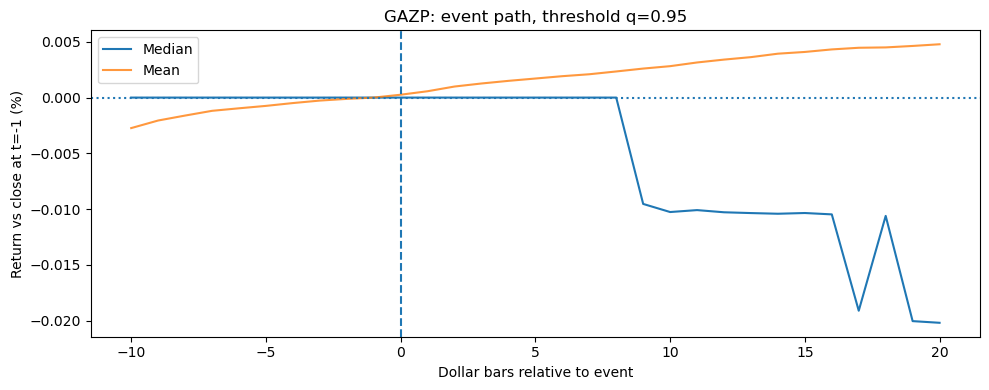

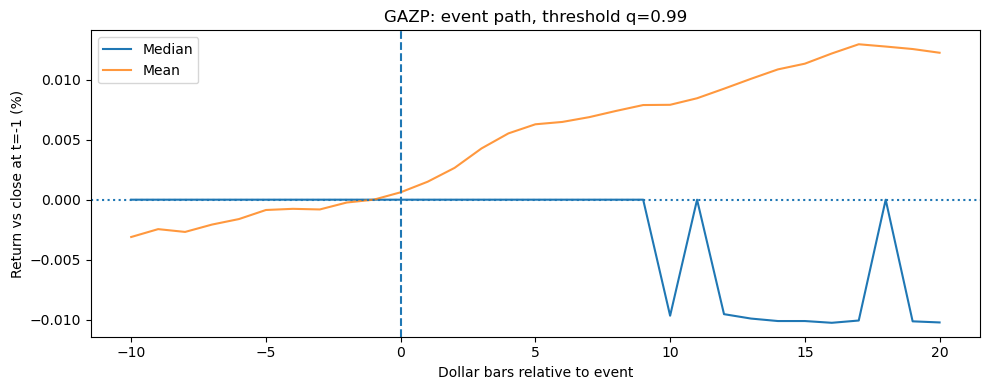

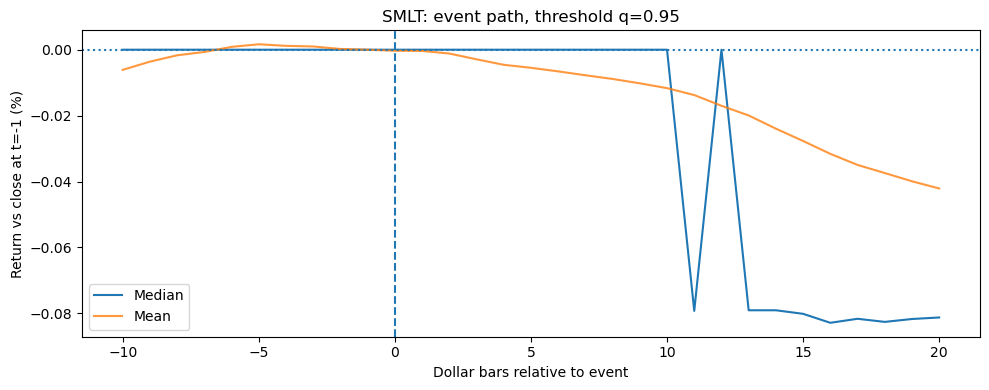

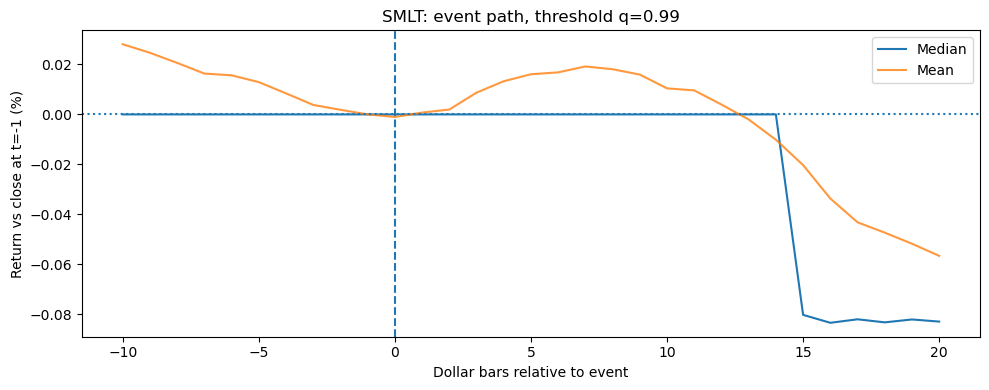

In [6]:
event_path_rows = []
for ticker, obj in datasets.items():
    if ticker not in detected:
        continue
    bars = obj["bars"].reset_index(drop=True)
    cols = find_ohlc_columns(bars)
    close = pd.to_numeric(bars[cols["close"]], errors="coerce").to_numpy(float)
    ev = detected[ticker]["bar_events"]
    for _, e in ev.iterrows():
        i = int(e["bar_idx"])
        if i < PRE_EVENT_BARS or i + POST_EVENT_BARS >= len(bars):
            continue
        base = close[i-1]
        if not np.isfinite(base) or base == 0:
            continue
        for k in range(-PRE_EVENT_BARS, POST_EVENT_BARS + 1):
            j = i + k
            if np.isfinite(close[j]):
                event_path_rows.append({
                    "ticker": ticker, "quantile": float(e["quantile"]), "event_bar_idx": i,
                    "relative_bar": k, "relative_return_pct": (close[j] / base - 1) * 100,
                    "n_extreme_features": int(e["n_extreme_features"]),
                    "n_sources_triggered": int(e["n_sources_triggered"]),
                })
event_path = pd.DataFrame(event_path_rows)
if not event_path.empty:
    event_path_summary = (event_path.groupby(["ticker", "quantile", "relative_bar"])["relative_return_pct"]
                          .agg(n="count", mean="mean", median="median",
                               p10=lambda x: x.quantile(.10), p90=lambda x: x.quantile(.90))
                          .reset_index())
    for ticker in event_path_summary["ticker"].unique():
        for q in ANOMALY_QUANTILES:
            part = event_path_summary[(event_path_summary["ticker"] == ticker) & (event_path_summary["quantile"] == q)]
            if part.empty:
                continue
            plt.figure(figsize=(10, 4))
            plt.plot(part["relative_bar"], part["median"], label="Median")
            plt.plot(part["relative_bar"], part["mean"], label="Mean", alpha=.8)
            plt.axvline(0, linestyle="--")
            plt.axhline(0, linestyle=":")
            plt.title(f"{ticker}: event path, threshold q={q}")
            plt.xlabel("Dollar bars relative to event")
            plt.ylabel("Return vs close at t=-1 (%)")
            plt.legend()
            plt.tight_layout()
            plt.show()
else:
    event_path_summary = pd.DataFrame()
    print("Недостаточно событий с полным окном для event-path графика.")


## 7. Экспорт компактных результатов

Экспортируются сводки и таблицы событий. Не сохраняются огромные полные feature matrices. Файл `feature_anomaly_events.csv` может быть объёмным, потому что одно событие на баре может содержать несколько экстремальных признаков.

In [7]:
def concat_nonempty(frames):
    frames = [x for x in frames if isinstance(x, pd.DataFrame) and not x.empty]
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

feature_events_all = concat_nonempty([x["feature_events"] for x in detected.values()])
bar_events_all = concat_nonempty([x["bar_events"] for x in detected.values()])
outcomes_all = concat_nonempty(list(outcomes_by_ticker.values()))
controls_all = concat_nonempty(list(matched_controls_by_ticker.values()))
pre_event_all = concat_nonempty(list(pre_event_by_ticker.values()))

exports = {
    "ticker_summary.csv": ticker_summary,
    "feature_anomaly_summary.csv": feature_summary,
    "event_control_comparison.csv": event_control_comparison,
    "event_outcome_summary.csv": outcome_summary,
    "event_bar_list.csv": bar_events_all,
    "feature_anomaly_events.csv": feature_events_all,
    "event_outcomes_and_controls.csv": outcomes_all,
    "event_path_summary.csv": event_path_summary,
}
for filename, frame in exports.items():
    if isinstance(frame, pd.DataFrame) and not frame.empty:
        frame.to_csv(OUT_DIR / filename, index=False)
        print(f"Saved {filename}: {len(frame):,} rows")
    else:
        print(f"Skipped {filename}: no rows")
print("\\nOutput directory:", OUT_DIR.resolve())


Saved ticker_summary.csv: 4 rows
Saved feature_anomaly_summary.csv: 1,604 rows
Saved event_control_comparison.csv: 20 rows
Saved event_outcome_summary.csv: 160 rows
Saved event_bar_list.csv: 16,021 rows
Saved feature_anomaly_events.csv: 315,792 rows
Saved event_outcomes_and_controls.csv: 95,622 rows
Saved event_path_summary.csv: 124 rows
\nOutput directory: C:\Users\Сергей Кравцов\sc_anomaly_event_study_outputs


## 8. Как интерпретировать результат и что НЕ делать

1. **Сначала частота событий.** Если на каком-то тикере/пороге слишком мало событий, сравнения по нему неубедительны.
2. **Смотри отдельно каждый источник и каждый тикер.** Не смешивай всё в один средний эффект.
3. **Сравнивай с контролем.** Если аномальные бары просто совпадают с повышенной волатильностью, контроль в похожем режиме должен уменьшить ложное впечатление о сигнале.
4. **Проверяй направление и абсолютное движение отдельно.** Аномалия может предсказывать повышенную волатильность, не предсказывая сторону.
5. **Не называй разницу прибыльной стратегией.** Доходности здесь close-to-close и не включают задержку реакции, spread, комиссии и проскальзывание.
6. **Не делай вывод о манипуляции/инсайде/фондах.** Эти данные сами по себе не устанавливают личность или намерение участника.
7. **Следующий шаг только после чтения результатов:** выбрать 1–3 заранее объяснимых типа событий и проверить их на отложенном временном периоде, с исполнимыми правилами входа/выхода и издержками.

### Ограничения текущей версии
- Rolling пороги причинные, но простая rolling-медиана/квантиль может быть чувствительна к разрывам и смене режима.
- Квантильные пороги по отдельным признакам могут создавать много коррелированных срабатываний; поэтому бар-события агрегируются.
- Контрольная группа сопоставляется по квинтилю прошлой волатильности, но пока не по часу торгов, spread и ликвидности.
- Пересекающиеся event windows не независимы; средние и медианы — разведочная статистика, не формальное доказательство значимости.
- Полный Temporal Audit здесь не перезапускается; используется тот же причинный join pipeline и наличие provenance полей из текущей архитектуры.
